# The lean: evaluation

**The strategy.** An hour before tipoff, a small boosted-trees model predicts how far the Polymarket home-win price will move by tipoff. It uses nine signals: the price's move over the last 23 hours, 7 hours, 3 hours, 1 hour and 15 minutes, the gap between the sportsbook-implied probability and the price, and the sportsbook line's move over three horizons. When the predicted move is large enough, bid one cent under the price on the side expected to rise and hold to the final result.

**The seasons.**
- **DEV, 2024–25.** The model is fitted here. DEV results are cross-validated over ten blocks of days, but the strategy was also chosen here, so they are optimistic.
- **TEST, 2025–26, and 2026–27 to date.** One fit on all of DEV, with the DEV threshold. Nothing was fitted on these seasons.

**The assumptions.** Every bet is a flat stake, and every bid is assumed to be filled at one cent under the price an hour before tipoff. The fill assumption is the weakest part; the section on it shows what the result is without it.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

sys.path.insert(0, str(Path.cwd()))
from mm_nba import lean

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .3})
LABEL = {"dev": "DEV 2024-25", "test": "TEST 2025-26", "new": "2026-27 to date"}
STAKE, START = lean.FLAT_STAKE, lean.START_BANKROLL

games = lean.load_games()
bets, floor = lean.backtest(games)
splits = list(pd.unique(games.split))
groups = {**{LABEL[s]: [s] for s in splits}, "never used to fit": [s for s in splits if s != "dev"], "all seasons": splits}
days = {s: sorted(games.game_date_et[games.split == s].unique()) for s in splits}
daily = {s: bets[bets.split == s].groupby("game_date_et").pnl.sum().reindex(days[s], fill_value=0.0) for s in splits}
season_days = np.mean([len(days[s]) for s in ("dev", "test")])            # game days in a full season
show = lambda t: "{:+.1f} ({:+.1f} to {:+.1f})".format(*t)
interval = lambda b, values: show(lean.mean_interval(values, b.game_date_et))
display(Markdown(f"**{len(games):,} games, {len(bets):,} bets.** A game is bet when the predicted move is at least {floor:.2f} cents either way "
                 f"(the {lean.BET_SHARE:.0%} of DEV games with the largest predictions). Flat \\${STAKE:,.0f} bets, \\${START:,.0f} starting bankroll."))

C:\Users\antho\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\antho\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\antho\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\antho\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\antho\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

**2,423 games, 1,167 bets.** A game is bet when the predicted move is at least 0.13 cents either way (the 50% of DEV games with the largest predictions). Flat \$50 bets, \$1,000 starting bankroll.

## Results by season

In [2]:
def metrics(names):
    b, d, g = bets[bets.split.isin(names)], pd.concat([daily[s] for s in names]), games[games.split.isin(names)]
    curve = START + d.cumsum()
    roi = 100 * b.pnl / STAKE
    boot = np.array([lean.mean_interval(roi, b.game_date_et, draws=1, seed=i)[1] for i in range(2000)])
    return {"games": len(g), "bets": len(b), "games bet %": 100 * len(b) / len(g), "bets won %": 100 * b.won.mean(),
            "average price of our side": b.price.mean(), "amount bet $": STAKE * len(b), "profit $": b.pnl.sum(),
            "return per dollar bet % (95%)": show(lean.mean_interval(roi, b.game_date_et)),
            "chance the true return is below zero %": 100 * (boot <= 0).mean(),
            "true edge, cents per share (95%)": interval(b, 100 * (b.won - b.price)),
            "price move our way by tipoff, cents (95%)": interval(b, b.move),
            "dollars won per dollar lost": b.pnl[b.pnl > 0].sum() / -b.pnl[b.pnl < 0].sum(),
            "daily profit: mean $": d.mean(), "daily profit: st. dev. $": d.std(),
            "Sharpe ratio, per full season": d.mean() / d.std() * np.sqrt(season_days),
            "game days with a profit %": 100 * (d > 0).sum() / (d != 0).sum(), "best day $": d.max(), "worst day $": d.min(),
            "largest drawdown $": (curve.cummax().clip(lower=START) - curve).max(),
            "longest run of losing bets": int(max((len(run) for run in "".join("L" if not w else " " for w in b.won).split()), default=0))}


summary = pd.DataFrame({name: metrics(names) for name, names in groups.items()})
display(summary.style.format(lambda v: v if isinstance(v, str) else f"{v:,.2f}" if abs(v) < 10 else f"{v:,.0f}"))

,DEV 2024-25,TEST 2025-26,2026-27 to date,never used to fit,all seasons
games,"1,121","1,132",170,"1,302","2,423"
bets,562,541,64,605,"1,167"
games bet %,50,48,38,46,48
bets won %,57,56,55,56,56
average price of our side,0.53,0.55,0.54,0.55,0.54
amount bet $,"28,100","27,050","3,200","30,250","58,350"
profit $,"3,275","1,357",-157,"1,199","4,474"
return per dollar bet % (95%),+11.7 (+3.4 to +20.2),+5.0 (-4.1 to +14.5),-4.9 (-28.2 to +19.3),+4.0 (-4.7 to +13.1),+7.7 (+1.7 to +14.1)
chance the true return is below zero %,0.45,15,65,18,0.60
"true edge, cents per share (95%)",+3.9 (+0.8 to +7.1),+1.0 (-2.6 to +4.8),+0.6 (-10.8 to +12.7),+1.0 (-2.5 to +4.5),+2.4 (+0.0 to +4.8)


## The bankroll

One continuous curve; the horizontal axis counts game days, so the summers take no space. The lower panel is how far the bankroll sits below its earlier peak.

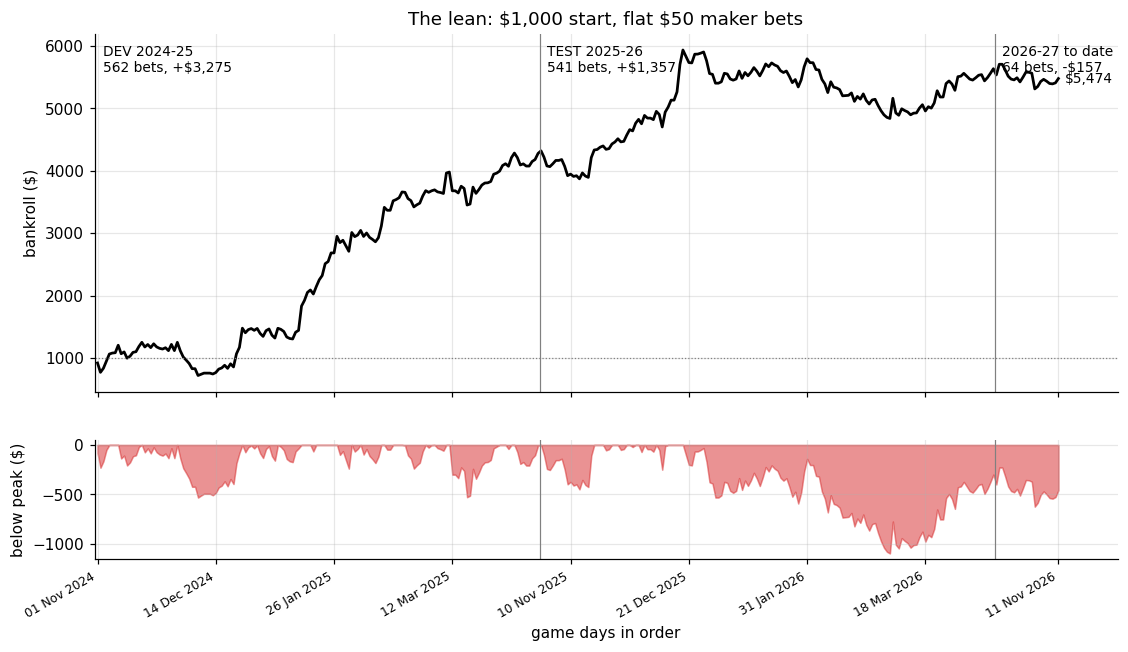

In [3]:
everything = pd.concat([daily[s] for s in splits])
curve = START + everything.cumsum()
x = np.arange(1, len(curve) + 1)
fig, (top, low) = plt.subplots(2, 1, figsize=(12, 6.2), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
top.plot(x, curve.values, color="k", lw=1.8)
top.axhline(START, color="grey", lw=.8, ls=":")
low.fill_between(x, -(curve.cummax().clip(lower=START) - curve).values, 0, color="C3", alpha=.5)
edge = 0
for s in splits:
    profit, n = daily[s].sum(), len(daily[s])
    for ax in (top, low):
        if edge:
            ax.axvline(edge + .5, color="grey", lw=.8)
    top.text(edge + 3, 0.97, f"{LABEL[s]}\n{(bets.split == s).sum():,} bets, {'-' if profit < 0 else '+'}\\${abs(profit):,.0f}",
             transform=top.get_xaxis_transform(), va="top", fontsize=9)
    edge += n
ticks = np.unique(np.r_[np.arange(0, len(curve) - 15, 40), len(curve) - 1])
low.set_xticks(ticks + 1)
low.set_xticklabels([pd.Timestamp(curve.index[i]).strftime("%d %b %Y") for i in ticks], rotation=30, ha="right", fontsize=8)
top.annotate(f"\\${curve.iloc[-1]:,.0f}", (x[-1], curve.iloc[-1]), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
top.set_xlim(0, len(curve) + 20)
top.set_ylabel("bankroll ($)")
low.set_ylabel("below peak ($)")
low.set_xlabel("game days in order")
top.set_title(f"The lean: \\${START:,.0f} start, flat \\${STAKE:,.0f} maker bets")
plt.show()

## Does it predict the price move?

The model is trained to predict the last-hour price move, so this is the direct test of it. If the price moves our way after the bid, we bought cheap.

In [4]:
later = games[games.split != "dev"]
dev = games[games.split == "dev"]
predicted = pd.concat([dev.assign(estimate=lean.cross_validated(dev)), later.assign(estimate=lean.estimate(dev, later))])
rows = {}
for name, names in groups.items():
    p, b = predicted[predicted.split.isin(names)], bets[bets.split.isin(names)]
    rows[name] = {"correlation of predicted and actual move, all games": np.corrcoef(p.estimate, p.move)[0, 1],
                  "games where the price moved the predicted way %": 100 * (np.sign(p.estimate) == np.sign(p.move))[p.move != 0].mean(),
                  "bets where the price moved our way %": 100 * (b.move > 0).sum() / (b.move != 0).sum(),
                  "average move our way on bets, cents (95%)": interval(b, b.move)}
display(pd.DataFrame(rows).style.format(lambda v: v if isinstance(v, str) else f"{v:,.2f}" if abs(v) < 10 else f"{v:,.0f}"))

unseen = bets[bets.split != "dev"]
size = pd.cut(unseen.estimate.abs(), [floor, *np.quantile(unseen.estimate.abs(), [1 / 3, 2 / 3]), np.inf], include_lowest=True)
display(Markdown("**TEST and 2026-27 bets, by the size of the predicted move** (a real signal should pay more where it is stronger)"))
display(unseen.groupby(size, observed=True).apply(lambda b: pd.Series({
    "bets": len(b), "average move our way, cents": b.move.mean(), "bets won %": 100 * b.won.mean(), "average price": 100 * b.price.mean(),
    "return per dollar bet %": 100 * b.pnl.mean() / STAKE}), include_groups=False).rename_axis("predicted move, cents").round(1))

,DEV 2024-25,TEST 2025-26,2026-27 to date,never used to fit,all seasons
"correlation of predicted and actual move, all games",0.26,0.14,0.10,0.14,0.21
games where the price moved the predicted way %,59,58,53,57,58
bets where the price moved our way %,66,60,40,58,62
"average move our way on bets, cents (95%)",+0.6 (+0.4 to +0.8),+0.2 (+0.0 to +0.4),-0.1 (-0.7 to +0.5),+0.2 (+0.0 to +0.4),+0.4 (+0.3 to +0.5)


**TEST and 2026-27 bets, by the size of the predicted move** (a real signal should pay more where it is stronger)

,bets,"average move our way, cents",bets won %,average price,return per dollar bet %
"predicted move, cents",,,,,
"(0.127, 0.269]",207.0,0.0,57.5,58.5,1.3
"(0.269, 0.602]",201.0,0.0,53.2,54.4,-2.1
"(0.602, inf]",197.0,0.5,55.8,50.5,13.0


## Where the profit comes from

TEST and 2026–27 bets only, split four ways. Small groups have wide intervals; read these as a check for a result that depends on one corner, not as separate strategies.

In [5]:
def breakdown(key, title):
    table = unseen.groupby(key, observed=True).apply(lambda b: pd.Series({
        "bets": len(b), "bets won %": round(100 * b.won.mean(), 1), "profit $": round(b.pnl.sum()),
        "return per dollar bet % (95%)": interval(b, 100 * b.pnl / STAKE)}), include_groups=False)
    display(Markdown(f"**{title}**"))
    display(table.rename_axis(None))


breakdown(unseen.side.map({"home": "home team", "away": "away team"}), "By the side we bid on")
breakdown(np.where(unseen.price >= 0.5, "favourite", "underdog"), "By favourite or underdog")
breakdown(pd.cut(unseen.price, [0, .3, .45, .55, .7, 1]).astype(str), "By the price of our side")
breakdown(pd.to_datetime(unseen.game_date_et).dt.strftime("%Y-%m"), "By month")

**By the side we bid on**

,bets,bets won %,profit $,return per dollar bet % (95%)
away team,229,52.8,1239,+10.8 (-5.2 to +27.3)
home team,376,57.2,-40,-0.2 (-9.8 to +9.6)


**By favourite or underdog**

,bets,bets won %,profit $,return per dollar bet % (95%)
favourite,386,66.3,509,+2.6 (-4.2 to +9.7)
underdog,219,36.5,691,+6.3 (-13.8 to +27.2)


**By the price of our side**

,bets,bets won %,profit $,return per dollar bet % (95%)
"(0.0, 0.3]",70,18.6,-74,-2.1 (-48.3 to +49.4)
"(0.3, 0.45]",92,42.4,571,+12.4 (-17.6 to +41.9)
"(0.45, 0.55]",121,44.6,-466,-7.7 (-24.7 to +9.4)
"(0.55, 0.7]",207,66.7,998,+9.6 (-1.6 to +21.6)
"(0.7, 1.0]",115,80.0,170,+3.0 (-6.3 to +11.5)


**By month**

,bets,bets won %,profit $,return per dollar bet % (95%)
2025-10,2,50.0,42,+41.5 (+41.5 to +41.5)
2025-11,88,54.5,252,+5.7 (-14.3 to +28.2)
2025-12,97,54.6,831,+17.1 (-11.2 to +51.1)
2026-01,133,60.9,390,+5.9 (-7.8 to +19.6)
2026-02,92,50.0,-658,-14.3 (-28.3 to +3.2)
2026-03,100,56.0,426,+8.5 (-15.8 to +32.3)
2026-04,29,55.2,74,+5.1 (-21.9 to +25.0)
2026-10,33,51.5,-58,-3.5 (-39.1 to +27.9)
2026-11,31,58.1,-100,-6.4 (-36.9 to +26.3)


## How much depends on the fill

The backtest assumes every bid one cent under the price is filled. In practice a resting bid fills more often when the price is falling toward it, which is when the bet is worse. These rows show the same bets under weaker assumptions.

In [6]:
def execution(b):
    won, price = b.won.to_numpy(), b.price.to_numpy()
    pay = lambda cost: np.where(won, STAKE / cost - STAKE, -STAKE)
    fee = lambda p: lean.FEE_RATE * p * (1 - p)
    cases = {"bid one cent under, filled, with the maker rebate (the backtest)": b.pnl.to_numpy(),
             "bid one cent under, filled, no rebate": pay(np.clip(price - lean.PRICE_OFFSET, 0.01, 0.99)),
             "filled at the price, no improvement": pay(price),
             "take the offer one cent over the price, paying the taker fee": pay(np.clip(price + lean.PRICE_OFFSET, 0.01, 0.99) + fee(price + lean.PRICE_OFFSET))}
    return {name: f"{pnl.sum():+,.0f} $, {show(lean.mean_interval(100 * pnl / STAKE, b.game_date_et, draws=2000))}" for name, pnl in cases.items()}


display(pd.DataFrame({name: execution(bets[bets.split.isin(names)]) for name, names in groups.items()}))
edge = 100 * (unseen.won - unseen.price).mean()
display(Markdown(f"On TEST and 2026-27 the bets won {edge:+.1f} cents per share more often than their price implied. "
                 f"That is the edge before any price improvement; the one-cent bid and the rebate add about {100 * lean.PRICE_OFFSET + 100 * lean.MAKER_REBATE * lean.FEE_RATE * 0.25:.1f} cents on top when filled."))

,DEV 2024-25,TEST 2025-26,2026-27 to date,never used to fit,all seasons
"bid one cent under, filled, with the maker rebate (the backtest)","+3,275 $, +11.7 (+3.4 to +20.2)","+1,357 $, +5.0 (-4.3 to +14.6)","-157 $, -4.9 (-28.1 to +19.2)","+1,199 $, +4.0 (-4.2 to +12.4)","+4,474 $, +7.7 (+1.9 to +13.9)"
"bid one cent under, filled, no rebate","+3,160 $, +11.2 (+3.0 to +19.8)","+1,257 $, +4.6 (-4.6 to +14.2)","-167 $, -5.2 (-28.3 to +18.9)","+1,090 $, +3.6 (-4.5 to +12.0)","+4,249 $, +7.3 (+1.6 to +13.5)"
"filled at the price, no improvement","+2,418 $, +8.6 (+0.6 to +16.8)","+622 $, +2.3 (-6.6 to +11.5)","-221 $, -6.9 (-29.6 to +16.8)","+401 $, +1.3 (-6.5 to +9.5)","+2,820 $, +4.8 (-0.7 to +10.8)"
"take the offer one cent over the price, paying the taker fee","+1,050 $, +3.7 (-3.6 to +11.3)","-561 $, -2.1 (-10.4 to +6.4)","-330 $, -10.3 (-32.1 to +12.4)","-891 $, -2.9 (-10.4 to +4.7)","+159 $, +0.3 (-4.9 to +5.9)"


On TEST and 2026-27 the bets won +1.0 cents per share more often than their price implied. That is the edge before any price improvement; the one-cent bid and the rebate add about 1.2 cents on top when filled.

## The one setting: how selective to be

The same model at four thresholds. The threshold is always a quantile of the DEV predictions. `config.json` holds the one in use (`bet_share`).

In [7]:
rows = {}
for share in (1.0, 0.75, 0.5, 0.25):
    b, f = lean.backtest(games, share)
    row = {"bid when the predicted move is at least, cents": f"{f:.2f}"}
    for name, names in groups.items():
        part = b[b.split.isin(names)]
        row[name] = f"{len(part):,} bets, {part.pnl.sum():+,.0f} $, {show(lean.mean_interval(100 * part.pnl / STAKE, part.game_date_et, draws=2000))}"
    rows[f"largest {share:.0%} of predictions" + (" (in use)" if share == lean.BET_SHARE else "")] = row
display(pd.DataFrame(rows).T)

,"bid when the predicted move is at least, cents",DEV 2024-25,TEST 2025-26,2026-27 to date,never used to fit,all seasons
largest 100% of predictions,0.00,"1,121 bets, +4,777 $, +8.5 (+0.6 to +16.6)","1,132 bets, +1,074 $, +1.9 (-4.8 to +8.7)","170 bets, -818 $, -9.6 (-23.6 to +6.2)","1,302 bets, +256 $, +0.4 (-5.5 to +6.9)","2,423 bets, +5,033 $, +4.2 (-0.7 to +9.3)"
largest 75% of predictions,0.05,"841 bets, +2,448 $, +5.8 (-1.4 to +13.3)","779 bets, +1,212 $, +3.1 (-5.0 to +11.4)","100 bets, -336 $, -6.7 (-25.0 to +11.7)","879 bets, +876 $, +2.0 (-5.3 to +9.6)","1,720 bets, +3,324 $, +3.9 (-1.6 to +9.0)"
largest 50% of predictions (in use),0.13,"562 bets, +3,275 $, +11.7 (+3.4 to +20.2)","541 bets, +1,357 $, +5.0 (-4.3 to +14.6)","64 bets, -157 $, -4.9 (-28.1 to +19.2)","605 bets, +1,199 $, +4.0 (-4.2 to +12.4)","1,167 bets, +4,474 $, +7.7 (+1.9 to +13.9)"
largest 25% of predictions,0.44,"281 bets, +1,610 $, +11.5 (-1.1 to +24.1)","258 bets, +1,378 $, +10.7 (-3.0 to +24.8)","20 bets, +84 $, +8.4 (-30.3 to +48.4)","278 bets, +1,461 $, +10.5 (-3.5 to +24.1)","559 bets, +3,071 $, +11.0 (+1.5 to +20.8)"


## Stake size

Flat stakes on a small bankroll can go bust in a bad run. These rows replay the same bets in order, staking a fixed share of the current bankroll instead.

In [8]:
def replay(share):
    bankroll, low, peak, worst = START, START, START, 0.0
    for stake_return in (bets.pnl / STAKE):
        bankroll *= 1 + share * stake_return
        peak = max(peak, bankroll)
        low, worst = min(low, bankroll), max(worst, 1 - bankroll / peak)
    return {"final bankroll $": round(bankroll), "lowest bankroll $": round(low), "largest drawdown %": round(100 * worst, 1)}


flat = START + bets.pnl.cumsum()
rows = {f"flat ${STAKE:,.0f} ({STAKE / START:.0%} of the starting bankroll)": {"final bankroll $": round(flat.iloc[-1]), "lowest bankroll $": round(flat.min()),
        "largest drawdown %": round(100 * (1 - flat / flat.cummax().clip(lower=START)).max(), 1)}}
rows.update({f"{share:.0%} of the current bankroll": replay(share) for share in (0.01, 0.02, 0.05)})
display(pd.DataFrame(rows).T)

,final bankroll $,lowest bankroll $,largest drawdown %
flat $50 (5% of the starting bankroll),5474.0,708.0,44.6
1% of the current bankroll,2258.0,937.0,22.5
2% of the current bankroll,4357.0,868.0,41.4
5% of the current bankroll,12853.0,640.0,78.7
